# Waterbirds: tabela de exatidão média e worst-group (Pessoa C)
Lê `results/raw/waterbirds.csv` (escrito por `train_last_layer.py`) e gera a tabela e a figura para os slides.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'waterbirds' else Path.cwd()
df = pd.read_csv(ROOT / 'results' / 'raw' / 'waterbirds.csv')
df['train_acc'] *= 100; df['test_acc'] *= 100; df['worst_group_acc'] *= 100
names = {'erm': 'ERM', 'fishr': 'Fishr (ambientes verdadeiros)', 'fishr_random_envs': 'Fishr (ambientes aleatórios)'}
g = df.groupby('method')
tab = pd.DataFrame({
    'Método': [names[m] for m in names],
    'Hiperparâmetros': [df[df.method == m].setting.iloc[0] for m in names],
    'Treino (%)': [f"{g.train_acc.mean()[m]:.1f} ± {g.train_acc.std()[m]:.1f}" for m in names],
    'Teste, média (%)': [f"{g.test_acc.mean()[m]:.1f} ± {g.test_acc.std()[m]:.1f}" for m in names],
    'Teste, worst-group (%)': [f"{g.worst_group_acc.mean()[m]:.1f} ± {g.worst_group_acc.std()[m]:.1f}" for m in names],
})
print('seeds por método:', g.seed.nunique().to_dict())
tab

seeds por método: {'erm': 5, 'fishr': 5, 'fishr_random_envs': 5}


,Método,Hiperparâmetros,Treino (%),"Teste, média (%)","Teste, worst-group (%)"
0,ERM,l2=0.001,98.9 ± 0.0,94.7 ± 0.1,61.2 ± 0.7
1,Fishr (ambientes verdadeiros),"lambda=1e+07,l2=0.1",99.2 ± 0.1,95.6 ± 0.2,70.2 ± 3.7
2,Fishr (ambientes aleatórios),"lambda=1e+06,l2=0.1",99.3 ± 0.1,95.8 ± 0.2,66.9 ± 2.2


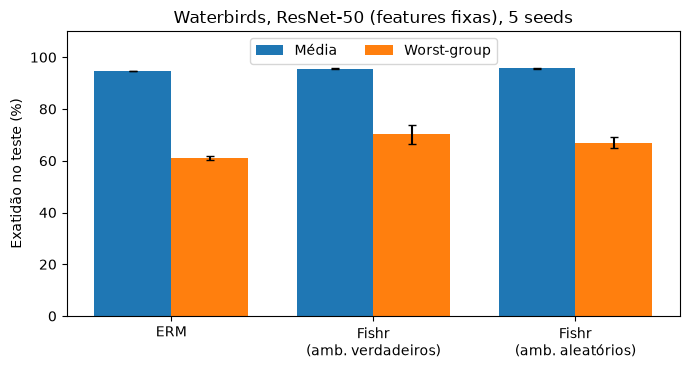

In [2]:
out = ROOT / 'results' / 'figures'; out.mkdir(parents=True, exist_ok=True)
tab.to_csv(out / 'waterbirds_table.csv', index=False)
(out / 'waterbirds_table.md').write_text(tab.to_markdown(index=False), encoding='utf-8')

fig, ax = plt.subplots(figsize=(7, 3.8))
x = range(len(names)); w = 0.38
for k, (col, lab) in enumerate([('test_acc', 'Média'), ('worst_group_acc', 'Worst-group')]):
    m = [g[col].mean()[n] for n in names]; s = [g[col].std()[n] for n in names]
    ax.bar([i + (k - 0.5) * w for i in x], m, w, yerr=s, capsize=3, label=lab)
ax.set_xticks(list(x)); ax.set_xticklabels(['ERM', 'Fishr\n(amb. verdadeiros)', 'Fishr\n(amb. aleatórios)'])
ax.set_ylabel('Exatidão no teste (%)'); ax.set_title('Waterbirds, ResNet-50 (features fixas), 5 seeds')
ax.set_ylim(0, 110); ax.legend(loc='upper center', ncol=2); fig.tight_layout()
fig.savefig(out / 'waterbirds_table.png', dpi=200); fig.savefig(out / 'waterbirds_table.pdf')